# Stalled-loop detection

**Recipe 51** · Level 4 (Advanced) · Decision type: `Choice`

Classify progress across recorded agent turns as advancing, repeating, regressing, or complete so Python can apply a continue, change-strategy, or stop policy.

Sources:

- S02: [TypeSafe AI: Primitives (Questions)](https://docs.typesafe.ai/primitives)
- S03: [TypeSafe AI: Confidence](https://docs.typesafe.ai/confidence)
- S04: [TypeSafe AI: How to build with TypeSafe](https://docs.typesafe.ai/concepts/how-to-build-with-system-one)
- S06: [TypeSafe AI: Cookbooks](https://docs.typesafe.ai/cookbooks)

## What you will build

An agent works toward a goal one turn at a time: it takes an action, observes a result, and writes itself a note. Sometimes it gets stuck: it runs the same failing command again, rewords a search that already found nothing, or undoes work it had finished. This recipe builds a supervisor for such a loop. At every checkpoint (every turn after the first) Python renders the goal and the turns so far, and Jev answers one narrow `Choice`: compared with the turns before it, is the latest turn `advancing`, `repeating`, `regressing` or `complete`, or is it `unclear` from what is shown? Everything after that judgment is code: a [confidence gate](../../docs/glossary.md#confidence-gate) frozen on `validation`, a fixed table that turns a label into *continue*, *change strategy* or *stop*, a limit of one strategy change per transcript, and a hard turn budget that stops any transcript whatever the answers say.

The transcripts are recorded, so the supervisor runs in shadow mode: it reads each transcript turn by turn and records where it *would* have changed the agent's strategy or stopped it, without the recorded agent ever receiving that instruction. That is what makes the evaluation possible: each checkpoint carries a gold progress label, the first turn labelled `repeating` or `regressing` is the transcript's stall point, and the recipe measures label accuracy and the **detection delay**, how many turns after the stall point the supervisor first intervened.

## Setup and run mode

The notebook runs from its own folder with the standard library and `jev_cookbook` only. `get_backend(fixtures=...)` replays the stored answers in `fixtures/responses.json` offline; setting `JEV_COOKBOOK_LIVE=1` (see the README) swaps in live calls to the same question definitions and changes nothing else. `run_header` states which mode ran. Two labels may follow a number below. `(a pipeline check, not a Jev result)` marks a synthetic or scripted run; a recorded or live run does not print it, and its header says which mode ran. `(a selection step, not a reported result)` marks a line that is not a result to report, such as a number from `validation`, the split settings are chosen on, or a count of the items the frozen rule queues or would queue. A line with neither label, such as an individual answer or a per-example line, still comes from the mode the header names.

Every checkpoint is decided once: `decide` caches answers by example id, so a checkpoint shown up close and later replayed by the supervisor is never requested twice.

In [1]:
from collections import Counter, defaultdict

from jev_cookbook import AuditedBackend, get_backend, load_helpers
from jev_cookbook.evaluation import (
    accuracy,
    confusion_matrix,
    evaluate_outcomes,
    select_confidence_threshold,
)
from jev_cookbook.fixtures import load_inputs, load_labels, responses_path, select_split
from jev_cookbook.simulation import ActionLog, ReviewQueue
from jev_cookbook.style import (
    apply_style,
    plot_answer_probabilities,
    plot_confusion_matrix,
    run_header,
    show_answer,
)

apply_style()
helpers = load_helpers()  # this recipe's helpers.py, loaded by path
examples = load_inputs()
labels = load_labels()
backend = AuditedBackend(get_backend(fixtures=responses_path()), label="main")
questions = helpers.build_questions()
# N for the header is the number of checkpoints the metrics are about: validation and test.
# The demo transcript is shown but never scored.
scored = [e for e in examples if e.split not in ("train", "demo")]

offline = backend.mode in ("synthetic", "scripted")
check = " (a pipeline check, not a Jev result)" if offline else ""
# A number from the validation split is a selection step, not a result, in every run mode.
selection = " (a selection step, not a reported result)"

answered = {}


def decide(example):
    if example.id not in answered:
        state = helpers.build_state(example.fields)
        answered[example.id] = backend.decide(state, questions)["progress"]
    return answered[example.id]


def transcripts(split_examples):
    """Checkpoints grouped by transcript, each group in turn order."""
    grouped = defaultdict(list)
    for example in split_examples:
        grouped[example.fields["transcript"]].append(example)
    return {ref: sorted(group, key=lambda e: e.fields["turn"]) for ref, group in grouped.items()}


run_header(51, "Stalled-loop detection", backend=backend, n_examples=len(scored))
for split in ("validation", "test", "demo"):
    split_examples = select_split(examples, split)
    print(
        f"{split}: {len(transcripts(split_examples))} transcript(s), "
        f"{len(split_examples)} checkpoints"
    )

Recipe 51: Stalled-loop detection
Mode: offline replay of synthetic fixtures, pipeline check on a fixture sample of 50 examples
Metrics in this run are checks that the pipeline works. They are not Jev results.
validation: 6 transcript(s), 29 checkpoints
test: 6 transcript(s), 21 checkpoints
demo: 1 transcript(s), 2 checkpoints


## The state

The state is everything Jev sees, and Python builds it. Each example in `fixtures/inputs.jsonl` is one checkpoint: its `fields` carry the transcript reference, the checkpoint's turn number, the goal, and every turn up to and including that one. `helpers.build_state` passes on the goal and the turns, rendered oldest first with the latest marked; the transcript reference and the turn number stay in Python and are attached to what the supervisor decides, so no identifier passes through the model.

Each turn shows the agent's own note next to its action and result, on purpose. Agents report on themselves, and a note can be wrong: the transcript below is the demo, and its final note claims the suite is "nearly passing" while the result is the same two timeouts for the third time running.

In [2]:
import json

demo = transcripts(select_split(examples, "demo"))
demo_ref, demo_checkpoints = next(iter(demo.items()))
last = demo_checkpoints[-1]
print("Python has: transcript", last.fields["transcript"], "at turn", last.fields["turn"])
print("Jev sees:")
print(json.dumps(helpers.build_state(last.fields), indent=2))
print()
print(helpers.render_turns(last.fields["turns"]))

Python has: transcript R-301 at turn 3
Jev sees:
{
  "goal": "Get the integration suite green on the release branch.",
  "turns": "Turn 1\n  action: run_tests tests/integration\n  result: 2 failed: test_checkout_flow, test_refund_flow (timeout contacting payments-stub)\n  note: Two failures, both timeouts.\nTurn 2\n  action: run_tests tests/integration\n  result: 2 failed: test_checkout_flow, test_refund_flow (timeout contacting payments-stub)\n  note: Re-running to be sure.\nTurn 3 (latest)\n  action: run_tests tests/integration --verbose\n  result: 2 failed: test_checkout_flow, test_refund_flow (timeout contacting payments-stub)\n  note: Verbose output shows the suite is nearly passing."
}

Turn 1
  action: run_tests tests/integration
  result: 2 failed: test_checkout_flow, test_refund_flow (timeout contacting payments-stub)
  note: Two failures, both timeouts.
Turn 2
  action: run_tests tests/integration
  result: 2 failed: test_checkout_flow, test_refund_flow (timeout contacting pa

## The questions

There is one question, and it asks one thing: compared with the turns before it, how does the latest turn move the agent toward the goal? A `Choice` fits because the outcomes are exclusive and the policy needs exactly one. Python builds the option list from `helpers.OPTIONS` and writes a definition for each, so that neighbours do not overlap: `repeating` is redoing an earlier step and learning nothing new from it, even when it is reworded or run with a trivially different option; `regressing` is losing ground that had been gained; a genuinely different approach after a failure is `advancing`, even before it pays off. `unclear` is the fallback this use case needs: a result that is missing or cut off cannot be judged, and forcing it into one of the other four would make the policy act on a guess. The instructions tell Jev that the agent's note is a claim, not evidence.

A `Choice` answer's `confidence` is the top probability rescaled by the number of options, `(p_max - 1/n) / (1 - 1/n)` ([TypeSafe AI: Confidence](https://docs.typesafe.ai/confidence), S03): 0 when the top option has no more than an even share of the options, 1 when it holds all the probability.

In [3]:
progress = questions["progress"]
print(progress.instructions)
for name, description in progress.criteria.items():
    print(f"  {name:11s} {description}")
print(f"options: {len(progress.criteria)}")

An agent is working toward the goal below, one turn at a time. Each turn lists the action the agent took, the result it observed, and the agent's own note. Judging the latest turn against the turns before it, which describes the agent's progress toward the goal? Judge from the actions and the results; the agent's own note is a claim, not evidence.
  advancing   The latest turn moves the task forward: it produces a result the earlier turns did not have, fixes or narrows something they left open, or tries a genuinely different approach after one that did not work.
  repeating   The latest turn redoes something an earlier turn already did and learns nothing new from it: the same step, possibly reworded or with trivially different options, ending in the same result or the same error as before.
  regressing  The latest turn undoes or breaks progress an earlier turn had made: something that worked now fails, a result that was in place is removed or overwritten, or the task is further from th

## One answer up close

Before any aggregate, look at the answer for the demo checkpoint shown above: the chosen option, a probability for every option, the confidence, and the [provenance](../../docs/glossary.md#provenance) line, which here is always `synthetic`, because nothing in this recipe's fixtures came from a real call.

Choice: repeating (confidence 0.80)
  repeating   0.84  #################
  advancing   0.08  ##
  regressing  0.03  #
  complete    0.03  #
  unclear     0.02  
Provenance: synthetic


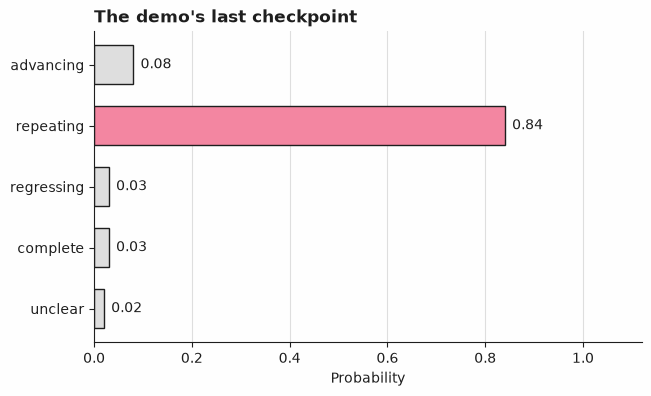

In [4]:
demo_answer = decide(last)
show_answer(demo_answer)
plot_answer_probabilities(demo_answer, title="The demo's last checkpoint")

The stored answer reads the action and the result rather than the note: the same two failures for the third time, behind a reworded command, is `repeating`. This demo carries no [gold label](../../docs/glossary.md#gold-label), the correct answer written into `fixtures/labels.jsonl` by whoever built the fixtures and used only to score an answer after the fact, because demo examples are never scored; the same pattern recurs, scored, in `validation` and `test`.

## Python's part

Jev supplies the judgment; what the supervisor does with it is code in `helpers.py`, and `tests/test_helpers.py` checks it against every possible answer.

- **The gate.** An answer below the threshold goes to a `ReviewQueue` with the reason `confidence below the threshold`, whatever it names, and the loop continues: the supervisor never changes strategy or stops on an answer it is not confident in. A confident `unclear` goes to the same queue with its own reason, because naming it says "a person should look", not what to do. This is the recipe's [review](../../docs/glossary.md#review) outcome.
- **The table.** `advancing` continues; `complete` stops the run as finished; `regressing` stops it at once, because a loop that is losing ground should not get another turn to lose more; `repeating` asks for a strategy change the first time.
- **The retry limit.** After `MAX_STRATEGY_CHANGES` strategy changes in one transcript, a further confident `repeating` stops the run.
- **The turn budget.** At turn `MAX_TURNS` the run stops with the reason `turn budget reached`, whatever the answer says, unless that answer has already stopped it. No answer can extend it.

A strategy change or a stop is recorded in an `ActionLog` (simulated: nothing is sent to any agent), and checkpoints after a stop are never consumed. The table is one pure function, `helpers.transition`, so the same rules also drive the gold run and the baseline below; `helpers.supervise` adds the gate and the writes.

The threshold is chosen here, on `validation`, and then frozen: `select_confidence_threshold(..., target_accuracy=1.0)` picks the lowest confidence at which every validation answer that clears it is right. A confident `unclear` never acts, so only answers that name one of the four actionable labels can set the bar.

In [5]:
print(f"MAX_TURNS = {helpers.MAX_TURNS}, MAX_STRATEGY_CHANGES = {helpers.MAX_STRATEGY_CHANGES}")
val_examples = select_split(examples, "validation")
val_answers = [decide(e) for e in val_examples]
val_gold = [labels[e.id] for e in val_examples]
actionable = [
    (a.choice == g, a.confidence)
    for a, g in zip(val_answers, val_gold, strict=True)
    if a.choice != helpers.UNCLEAR
]
threshold = select_confidence_threshold(
    [ok for ok, _ in actionable], [c for _, c in actionable], target_accuracy=1.0
)
print(f"answers that can set the bar: {len(actionable)} of {len(val_answers)}{selection}{check}")
print(f"chosen threshold, frozen from here on: {threshold:.4f}{selection}{check}")

demo_queue, demo_actions = ReviewQueue(), ActionLog()
demo_run = helpers.supervise(
    demo_ref,
    [(e.fields["turn"], decide(e)) for e in demo_checkpoints],
    threshold,
    queue=demo_queue,
    actions=demo_actions,
)
for step, example in zip(demo_run.steps, demo_checkpoints, strict=False):
    answer = decide(example)
    print(
        f"{demo_ref} turn {step.turn}: {answer.choice} at confidence {answer.confidence:.2f} "
        f"-> {step.decision} [{step.reason}]"
    )
print(f"stopped at turn {demo_run.stopped_at}: {demo_run.stop_reason}")
for entry in demo_actions.to_dicts():
    print(f"  action log: {entry['kind']} at turn {entry['step']}, executed={entry['executed']}")

MAX_TURNS = 8, MAX_STRATEGY_CHANGES = 1
answers that can set the bar: 28 of 29 (a selection step, not a reported result) (a pipeline check, not a Jev result)
chosen threshold, frozen from here on: 0.5000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
R-301 turn 2: repeating at confidence 0.60 -> change_strategy [repeating: change strategy]
R-301 turn 3: repeating at confidence 0.80 -> stop [still repeating after a strategy change]
stopped at turn 3: still repeating after a strategy change
  action log: change_strategy at turn 2, executed=False
  action log: stop at turn 3, executed=False


The demo walks the whole table in two checkpoints: a confident `repeating` asks for a strategy change, and the next confident `repeating`, with the one allowed change already used, stops the run. Both are entries in the action log, marked `executed=False`: the supervisor records what it would do and does nothing.

## Evaluation

The threshold was chosen and frozen above, on `validation`; `test` is used once, to report. The evaluation scores two things.

**Label accuracy** is the fraction of checkpoints whose raw `choice` matches the gold label, over every checkpoint in the split, whether or not the supervisor would still be running there. **Coverage**, accuracy among those answered and **risk** come from the rule's own decisions per checkpoint (`helpers.checkpoint_answered`, built on `helpers.transition`): a checkpoint is answered when the policy acts on it, so an answer below the gate and a confident `unclear` both count toward review, never toward [coverage](../../docs/glossary.md#coverage). They are computed with `evaluate_outcomes`, since the rule has a review branch (`unclear`) that is not a confidence comparison; [risk](../../docs/glossary.md#risk) is `1 - accuracy` among the answered.

**Detection delay** is about whole transcripts. A transcript's stall point is its first checkpoint whose gold label is `repeating` or `regressing` (`helpers.stall_onset`). The supervisor's first stall intervention is the first turn it changed strategy or stopped for `repeating` or `regressing`. The delay is the difference in turns: `0` means it intervened at the stall point itself. A stall it never intervened on is *missed* (including a run it stopped for another reason first), and an intervention before the stall point, or on a transcript that never stalls, is *early*, a false alarm. The mean delay is over detected stalls only, so it is printed beside the missed count and never alone.

One `validation` number cannot come out otherwise: the threshold is chosen so that every validation answer that clears it is right, so accuracy among the answered on `validation` is `1.0000` and its risk `0.0000` by construction. Those two lines describe the selection, not the rule; read `test` for that. In an offline run every number below is a check that the pipeline works, and its line says so.

In [6]:
def run_split(split_examples):
    """Supervise every transcript of a split; return the runs, the queue and the log."""
    queue, actions = ReviewQueue(), ActionLog()
    runs = {}
    for ref, checkpoints in transcripts(split_examples).items():
        answers = [(e.fields["turn"], decide(e)) for e in checkpoints]
        runs[ref] = helpers.supervise(ref, answers, threshold, queue=queue, actions=actions)
    return runs, queue, actions


def detections(split_examples, runs):
    found = []
    for ref, checkpoints in transcripts(split_examples).items():
        onset = helpers.stall_onset([(e.fields["turn"], labels[e.id]) for e in checkpoints])
        found.append(helpers.detection(runs[ref], onset))
    return found


def report(name, split_examples, runs, queue, actions, tag):
    answers = [decide(e) for e in split_examples]
    gold = [labels[e.id] for e in split_examples]
    took = [helpers.checkpoint_answered(a, threshold) for a in answers]
    right = [a.choice == g for a, g in zip(answers, gold, strict=True)]
    result = evaluate_outcomes(took, right)
    print(f"{name}, {len(split_examples)} checkpoints in {len(runs)} transcripts{tag}")
    print(f"label accuracy of the raw choice: {accuracy(gold, answers):.4f}{tag}")
    print(
        f"answered (coverage): {result.n_answered} of {result.n_total} "
        f"(coverage {result.coverage:.4f}){tag}"
    )
    print(f"accuracy among those answered: {result.accuracy:.4f}{tag}")
    print(f"risk among those answered: {result.risk:.4f}{tag}")
    found = detections(split_examples, runs)
    outcomes = Counter(d.outcome for d in found)
    delays = [d.delay for d in found if d.outcome == "detected"]
    stalled = sum(d.onset is not None for d in found)
    print(f"transcripts with a stall point: {stalled} of {len(found)}{tag}")
    print(
        f"stalls detected: {outcomes['detected']}, missed: {outcomes['missed']}, "
        f"early interventions (false alarms): {outcomes['early']}{tag}"
    )
    if delays:
        mean_delay = sum(delays) / len(delays)
        print(f"detection delay over the {len(delays)} detected, in turns: {delays}{tag}")
        print(f"mean detection delay over detected stalls: {mean_delay:.2f} turns{tag}")
    for d in found:
        print(
            f"  {d.transcript}: stall point {d.onset}, first intervention {d.intervened} -> {d.outcome}"
        )
    print(f"{name} action log: {len(actions)} entries{tag}")
    for (kind, rule), n in sorted(
        Counter((e["kind"], e["rule"]) for e in actions.to_dicts()).items()
    ):
        print(f"  {kind:16s} {rule:42s} {n}")
    print(f"{name} review queue: {len(queue)} entries{tag}")
    for reason, n in sorted(Counter(i["reason"] for i in queue.to_dicts()).items()):
        print(f"  {reason:38s} {n}")
    return found


val_runs, val_queue, val_actions = run_split(val_examples)
val_found = report(
    "validation", val_examples, val_runs, val_queue, val_actions, f"{selection}{check}"
)

validation, 29 checkpoints in 6 transcripts (a selection step, not a reported result) (a pipeline check, not a Jev result)
label accuracy of the raw choice: 0.8621 (a selection step, not a reported result) (a pipeline check, not a Jev result)
answered (coverage): 24 of 29 (coverage 0.8276) (a selection step, not a reported result) (a pipeline check, not a Jev result)
accuracy among those answered: 1.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
risk among those answered: 0.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
transcripts with a stall point: 4 of 6 (a selection step, not a reported result) (a pipeline check, not a Jev result)
stalls detected: 4, missed: 0, early interventions (false alarms): 0 (a selection step, not a reported result) (a pipeline check, not a Jev result)
detection delay over the 4 detected, in turns: [0, 1, 1, 0] (a selection step, not a reported result) (a pipeline check, not a Jev res

In [7]:
test_examples = select_split(examples, "test")
test_answers = [decide(e) for e in test_examples]
test_gold = [labels[e.id] for e in test_examples]
test_runs, test_queue, test_actions = run_split(test_examples)
test_found = report("test", test_examples, test_runs, test_queue, test_actions, check)
print(f"frozen gate from above: {threshold:.4f}{check}")

test, 21 checkpoints in 6 transcripts (a pipeline check, not a Jev result)
label accuracy of the raw choice: 0.8571 (a pipeline check, not a Jev result)
answered (coverage): 17 of 21 (coverage 0.8095) (a pipeline check, not a Jev result)
accuracy among those answered: 0.9412 (a pipeline check, not a Jev result)
risk among those answered: 0.0588 (a pipeline check, not a Jev result)
transcripts with a stall point: 4 of 6 (a pipeline check, not a Jev result)
stalls detected: 3, missed: 1, early interventions (false alarms): 0 (a pipeline check, not a Jev result)
detection delay over the 3 detected, in turns: [0, 1, 0] (a pipeline check, not a Jev result)
mean detection delay over detected stalls: 0.33 turns (a pipeline check, not a Jev result)
  R-201: stall point None, first intervention None -> no stall
  R-202: stall point 2, first intervention 2 -> detected
  R-203: stall point 4, first intervention 5 -> detected
  R-204: stall point 3, first intervention 3 -> detected
  R-205: stall 

On `test` the gate lets one wrong answer through (the cell after the confusion matrix names it), so accuracy among the answered is below `1.0000` and risk above `0.0000`. The detection lines show where that matters: the supervisor detects some of the stalled `test` transcripts, one of them a turn late, and misses one; the walk-throughs below follow a late one and the miss turn by turn. A miss is not always harmless, since a person still has to read the review queue, but a missed stall that is only ever reviewed takes no wrong action.

Test confusion matrix, gold rows by predicted columns (a pipeline check, not a Jev result):
  predicted ->      advancing   repeating  regressing    complete     unclear (a pipeline check, not a Jev result)
  gold advancing            7           1           0           1           0 (a pipeline check, not a Jev result)
  gold repeating            1           5           0           0           0 (a pipeline check, not a Jev result)
  gold regressing           0           0           1           0           0 (a pipeline check, not a Jev result)
  gold complete             0           0           0           4           0 (a pipeline check, not a Jev result)
  gold unclear              0           0           0           0           1 (a pipeline check, not a Jev result)


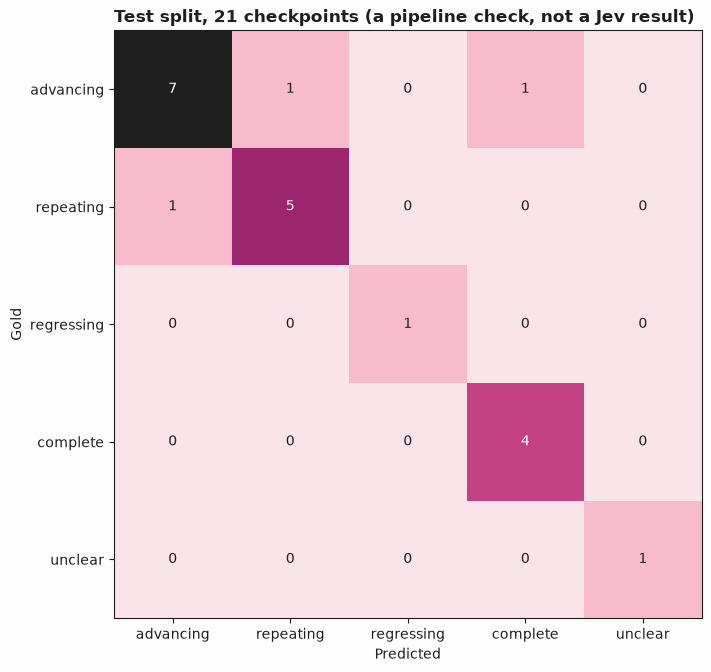

In [8]:
matrix = confusion_matrix(test_gold, test_answers, labels=list(helpers.OPTIONS))
width = max(len(label) for label in matrix.labels)
column = max(width, len(str(matrix.matrix.max())))
leader_width = max(width + len("gold "), len("predicted ->"))
header = "  ".join(f"{label:>{column}s}" for label in matrix.labels)
print(f"Test confusion matrix, gold rows by predicted columns{check}:")
print(f"  {'predicted ->':<{leader_width}s}  {header}{check}")
for gold_label, row in zip(matrix.labels, matrix.matrix.tolist(), strict=True):
    counts = "  ".join(f"{count:{column}d}" for count in row)
    leader = f"gold {gold_label:<{width}s}"
    print(f"  {leader:<{leader_width}s}  {counts}{check}")
plot_confusion_matrix(matrix, title=f"Test split, {len(test_examples)} checkpoints{check}")

In [9]:
print("Test checkpoints the raw choice got wrong, and what the policy made of them:")
decided = {(s.transcript, s.turn): s for run in test_runs.values() for s in run.steps}
for example, answer, gold in zip(test_examples, test_answers, test_gold, strict=True):
    if answer.choice != gold:
        step = decided.get((example.fields["transcript"], example.fields["turn"]))
        what = f"{step.decision} [{step.reason}]" if step else "not reached: the run had stopped"
        print(
            f"  {example.id}: gold {gold}, answered {answer.choice} "
            f"(confidence {answer.confidence:.2f}) -> {what}"
        )

Test checkpoints the raw choice got wrong, and what the policy made of them:
  t-retry-search-t4: gold repeating, answered advancing (confidence 0.70) -> continue [confident advancing]
  t-backup-space-t3: gold advancing, answered complete (confidence 0.30) -> review [confidence below the threshold]
  t-deploy-poll-t3: gold advancing, answered repeating (confidence 0.40) -> review [confidence below the threshold]


In [10]:
print("Checkpoints that look like a stall but are not, where the answer names one:")
for split_name, runs in (("validation", val_runs), ("test", test_runs)):
    tag = f"{selection}{check}" if split_name == "validation" else check
    decided = {(s.transcript, s.turn): s for run in runs.values() for s in run.steps}
    for example in select_split(examples, split_name):
        answer = decide(example)
        gold = labels[example.id]
        if gold not in helpers.STALLS and answer.choice in helpers.STALLS:
            step = decided[(example.fields["transcript"], example.fields["turn"])]
            print(
                f"  {split_name} {example.id}: gold {gold}, answered {answer.choice} "
                f"(confidence {answer.confidence:.2f}) -> {step.decision} [{step.reason}]{tag}"
            )

Checkpoints that look like a stall but are not, where the answer names one:
  validation v-table-migration-t4: gold advancing, answered repeating (confidence 0.30) -> review [confidence below the threshold] (a selection step, not a reported result) (a pipeline check, not a Jev result)
  test t-deploy-poll-t3: gold advancing, answered repeating (confidence 0.40) -> review [confidence below the threshold] (a pipeline check, not a Jev result)


These are the checkpoints that could have produced a false alarm: a new table migrated with a command that resembles the previous one, and a deploy status that moved on from the check before it. Neither one reached the policy as a confident stall, because both stored answers fall below the gate and went to review. That is a property of how the answers were written here, not of the policy: the table acts on any confident `repeating`, so a confident answer on a look-alike turn would be an early intervention, which the detection lines count as `early`.

### Two stalled transcripts, turn by turn

The two walk-throughs show the two ways the supervisor falls short of the gold stall point. `R-203` searches for a retry limit and its stall point is the turn that greps for a variable an earlier search had already failed to find; the stored answer for that turn is a confident `advancing`, so the supervisor continues, and it asks for a strategy change at the next turn, when the same search is run again case-insensitively. `R-206` polls a deploy: its stall point is a status check that returns the same step as the check before it, and both stored answers around it fall below the gate, so the supervisor leaves them for review and keeps going until the deploy finishes. Beside each run, the run the same table produces from the gold labels shows what a correct label at every turn would have led to.

In [11]:
for ref in ("R-203", "R-206"):
    walk = transcripts(test_examples)[ref]
    walk_run = test_runs[ref]
    gold_walk = helpers.label_run(ref, [(e.fields["turn"], labels[e.id]) for e in walk])
    steps = {s.turn: s for s in walk_run.steps}
    gold_steps = {s.turn: s for s in gold_walk.steps}
    print(f"{ref}: {walk[0].fields['goal']}")
    for example in walk:
        turn = example.fields["turn"]
        latest = example.fields["turns"][-1]
        answer = decide(example)
        ran = steps[turn].decision if turn in steps else "(stopped)"
        gold_ran = gold_steps[turn].decision if turn in gold_steps else "(stopped)"
        print(f"turn {turn}: {latest['action']}")
        print(f"         result: {latest['result']}")
        print(
            f"         gold {labels[example.id]:10s} answered {answer.choice:10s} "
            f"({answer.confidence:.2f})  supervisor: {ran:15s} gold run: {gold_ran}"
        )
    print(f"supervisor stopped at turn {walk_run.stopped_at}: {walk_run.stop_reason}")
    print(f"gold run stopped at turn {gold_walk.stopped_at}: {gold_walk.stop_reason}")
    print()

R-203: Find where the HTTP client's retry limit is set.
turn 2: search 'retries' in config/
         result: config/base.yaml:8  retries: ${RETRY_LIMIT}
         gold advancing  answered advancing  (0.80)  supervisor: continue        gold run: continue
turn 3: search 'RETRY_LIMIT' in config/
         result: no matches
         gold advancing  answered advancing  (0.60)  supervisor: continue        gold run: continue
turn 4: grep -rn RETRY_LIMIT config/
         result: no matches
         gold repeating  answered advancing  (0.70)  supervisor: continue        gold run: change_strategy
turn 5: grep -rni retry_limit config/
         result: no matches
         gold repeating  answered repeating  (0.60)  supervisor: change_strategy gold run: stop
turn 6: search 'RETRY_LIMIT' in deploy/
         result: deploy/prod.env:5  RETRY_LIMIT=4
         gold complete   answered complete   (0.80)  supervisor: stop            gold run: (stopped)
supervisor stopped at turn 6: task complete
gold run s

The table also shows the cost of a stop rule in shadow mode. In `R-203` the run the gold labels drive asks for a change at its stall point and stops one turn later, before this recorded agent found the answer by itself. Run live, a supervisor that changed the agent's strategy would have produced a different transcript, which a recorded run cannot show. That is the limit of evaluating a loop policy on recordings: they measure when the policy would intervene, not what would have happened after it did. `R-206` shows the other side: its gold run asks for a strategy change at the stall point, which the supervisor never does because it left those turns for review; both runs then stop at the same turn, when the deploy reports done.

### A baseline with no judgment

`helpers.exact_repeat_baseline` is the rule a supervisor could run with no model at all: a turn is `repeating` when its action and its result are identical, character for character, to an earlier turn's, and `advancing` otherwise. It never says `regressing`, `complete` or `unclear`. Its labels go through the same table (`helpers.label_run`, which treats every label as clearing the gate), so the difference between the two runs is only in the labels.

In [12]:
def baseline_report(name, split_examples, tag):
    groups = transcripts(split_examples)
    base_labels = [helpers.exact_repeat_baseline(e.fields["turns"]) for e in split_examples]
    gold = [labels[e.id] for e in split_examples]
    print(f"{name}: baseline label accuracy {accuracy(gold, base_labels):.4f}{tag}")
    found = []
    for ref, checkpoints in groups.items():
        labelled = [
            (e.fields["turn"], helpers.exact_repeat_baseline(e.fields["turns"]))
            for e in checkpoints
        ]
        onset = helpers.stall_onset([(e.fields["turn"], labels[e.id]) for e in checkpoints])
        found.append(helpers.detection(helpers.label_run(ref, labelled), onset))
    outcomes = Counter(d.outcome for d in found)
    delays = [d.delay for d in found if d.outcome == "detected"]
    print(
        f"{name}: baseline stalls detected {outcomes['detected']}, missed {outcomes['missed']}, "
        f"early {outcomes['early']}; delays of the detected {delays}{tag}"
    )
    return found


base_val = baseline_report("validation", val_examples, f"{selection}{check}")
base_test = baseline_report("test", test_examples, check)
print(
    f"test: raw choice label accuracy (for comparison) {accuracy(test_gold, test_answers):.4f}{check}"
)
for jev, base in zip(test_found, base_test, strict=True):
    if jev.onset is not None:
        print(f"  {jev.transcript}: supervisor {jev.outcome}, baseline {base.outcome}")

validation: baseline label accuracy 0.6897 (a selection step, not a reported result) (a pipeline check, not a Jev result)
validation: baseline stalls detected 2, missed 2, early 0; delays of the detected [0, 0] (a selection step, not a reported result) (a pipeline check, not a Jev result)
test: baseline label accuracy 0.5714 (a pipeline check, not a Jev result)
test: baseline stalls detected 2, missed 2, early 0; delays of the detected [0, 0] (a pipeline check, not a Jev result)
test: raw choice label accuracy (for comparison) 0.8571 (a pipeline check, not a Jev result)
  R-202: supervisor detected, baseline detected
  R-203: supervisor detected, baseline missed
  R-204: supervisor detected, baseline missed
  R-206: supervisor missed, baseline detected


The baseline catches exactly the loops that repeat a command character for character and misses the rest: a reworded search (`R-203`) and a regression (`R-204`) look like progress to it. It does catch `R-206`, the polling loop the supervisor missed, because two identical status checks returned identical results, and it catches it without a confidence gate, since the rule has no confidence to gate. Its lower label accuracy also reflects that it never names `complete`, `regressing` or `unclear` at all. These comparisons describe this fixture set, which was written so that both kinds of loop occur; they are not a claim about how Jev performs.

## What was and was not measured

What this run can say about Jev depends on its mode, which the cell below states from `backend.mode`: a synthetic or scripted run is a pipeline check only, on the fixture sample it ran against; a recorded or live run states the model the API returned and when, for exactly the checkpoints it covers. `N` below counts the checkpoints that carry a gold label, so it excludes the demo transcript. The stored answers in the offline run are probabilities written by hand, some of them wrong on purpose and one of them wrong and confident on `test`, so every number above describes this fixture set and not a model; nothing here says anything about how Jev performs, how fast it is or what it costs.

In [13]:
if offline:
    print(f"Provenance: {backend.mode}. Not measured live: a pipeline check, not a Jev result.")
    print(f"N: {len(val_examples)} validation and {len(test_examples)} test checkpoints{check}")
else:
    dates = ", ".join(getattr(backend, "recorded_dates", ()) or ()) or "this run"
    print(f"Provenance: {backend.mode}, model {backend.model}")
    print(f"Captured: {dates}")
    print(f"N: {len(val_examples)} validation and {len(test_examples)} test checkpoints")

Provenance: synthetic. Not measured live: a pipeline check, not a Jev result.
N: 29 validation and 21 test checkpoints (a pipeline check, not a Jev result)


### Live request audit

The cell below is this notebook's final code cell, on purpose: `backend.audit_json()` prints an ordered ledger of every `decide()` call the backend above made. [`request_budget.json`](request_budget.json) declares this notebook's live request count once. The recipe guard's `readme_budget_note_matches_request_audit` check compares the ledger, the declaration and the README's rendered paragraph against each other ([docs/backends.md](../../docs/backends.md#actual-calls-and-distinct-requests)). It holds no response content and says nothing about Jev's quality, speed or cost.

In [14]:
print(backend.audit_json())

JEV_REQUEST_AUDIT {"schema":2,"backends":[{"label":"main","decide_calls":52,"distinct_requests":52,"calls":[{"replay_key":"ad04ef9ea9a6d5b3a66e7ee6624c1a830a9128422e8e46a747c86d8240095f27","returned":true},{"replay_key":"458d17873b6f43dfe915556b89e4a698624aa5f144c0ea14bb4928689cf78080","returned":true},{"replay_key":"1e7fc63ae5363d8796ffef59447ada99251241c9c1aec19e3712a2550dbb0c63","returned":true},{"replay_key":"c1d3776cf2b61ecbee25454cd92713e606c8f776106757599b4c3bb3e96ccb60","returned":true},{"replay_key":"d3e6b026de1d9af2a254971a1d57ef10d88d54daa4e582badaf9913527e23e1f","returned":true},{"replay_key":"06442b1ad80dd96ee810a6f1273a7e1b765475acbc9c26692232c9125f538a23","returned":true},{"replay_key":"ef43dba7bc69f3e595c2dad54c82d2593fca9982c88f2d52660b5643ff409bc5","returned":true},{"replay_key":"02a0f12fc6341481179aff89c51a2557adee1952eed3f8f77d70e0f1bdc42b83","returned":true},{"replay_key":"3968ecee200d4c0cf3ba6d51bdc05c2316bc9f91e519b2bab24f927618e408b0","returned":true},{"replay_k

## Next steps

- Add a transcript to `TRANSCRIPTS` in `build_fixtures.py` (a loop that alternates between two failing commands is a good one: neither the exact-repeat baseline nor a single-turn comparison sees it at once), give it the answers you expect, run `python build_fixtures.py`, and see where the supervisor intervenes.
- Neighbouring recipes: [`29-tool-outcome-verification`](../29-tool-outcome-verification/) (`Choice`) judges whether one tool run did what was asked, the per-turn question this recipe's supervisor composes into a loop policy; [`43-failure-recovery-selection`](../43-failure-recovery-selection/) (`Choice`) picks the recovery once a failure is known; [`38-abstention-and-review-queues`](../38-abstention-and-review-queues/) (`Choice`) is the review-queue pattern used here for unconfident and `unclear` answers.